# Практика 8. Вариант 5
## Внутридневная активность: заказы и выручка по часам

**Цель работы:** изучить распределение заказов и выручки по часам суток,
найти часы пиковой активности, сравнить их по заказам и по выручке и
объяснить возможное расхождение.

**Задачи:**
1. Построить line chart количества заказов по часам.
2. Построить line chart выручки по часам.
3. Сравнить час максимума по заказам и по выручке.
4. Объяснить, почему они могут не совпадать.
5. Сделать вывод.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# ============================================================
# ГЕНЕРАЦИЯ ТЕСТОВЫХ ДАННЫХ (внешние файлы не нужны)
# ============================================================
np.random.seed(42)
n = 3000

# Генерируем время с реалистичным распределением по часам:
# пики — утро (9-11), обед (13), вечер (19-21), ночь — спад
hours_pool = np.concatenate([
    np.random.choice(range(0, 6),   200),   # ночь — мало
    np.random.choice(range(6, 12),  900),   # утро — пик
    np.random.choice(range(12, 18), 900),   # день — пик
    np.random.choice(range(18, 24), 1000),  # вечер — пик
])

df_orders = pd.DataFrame({
    "order_id": range(1, n + 1),
    "order_datetime": pd.to_datetime("2024-01-01") + pd.to_timedelta(
        np.random.randint(0, 90, n), unit="D"
    ) + pd.to_timedelta(hours_pool[:n], unit="h")
        + pd.to_timedelta(np.random.randint(0, 60, n), unit="m"),
    "price": np.random.uniform(100, 5000, n).round(2),
    "quantity": np.random.randint(1, 10, n),
    "status": np.random.choice(["completed", "cancelled", "pending"],
                                n, p=[0.8, 0.1, 0.1]),
})

# Несколько крупных заказов (чтобы час максимума по выручке мог отличаться)
df_orders.loc[5,   ["price", "quantity"]] = [45000, 8]
df_orders.loc[100, ["price", "quantity"]] = [38000, 6]
df_orders.loc[250, ["price", "quantity"]] = [52000, 3]

# Производные признаки
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]
df_orders["order_date"] = df_orders["order_datetime"].dt.date
df_orders["order_hour"] = df_orders["order_datetime"].dt.hour
df_orders["weekday"] = df_orders["order_datetime"].dt.day_name()

print("Размер датасета:", df_orders.shape)
print(df_orders.head())

Размер датасета: (3000, 9)
   order_id      order_datetime    price  quantity     status   revenue  \
0         1 2024-02-18 03:59:00  2086.81         8  completed  16694.48   
1         2 2024-01-21 04:35:00  4922.04         4  completed  19688.16   
2         3 2024-03-14 02:23:00  1532.02         3  completed   4596.06   
3         4 2024-03-04 04:53:00  1544.60         1  completed   1544.60   
4         5 2024-01-05 04:26:00  1837.29         9  completed  16535.61   

   order_date  order_hour   weekday  
0  2024-02-18           3    Sunday  
1  2024-01-21           4    Sunday  
2  2024-03-14           2  Thursday  
3  2024-03-04           4    Monday  
4  2024-01-05           4    Friday  


In [2]:
print(df_orders[["price", "quantity", "revenue"]].describe())

              price     quantity        revenue
count   3000.000000  3000.000000    3000.000000
mean    2541.767707     5.013333   12933.752853
std     1953.985416     2.558255   13058.606919
min      101.180000     1.000000     101.180000
25%     1281.795000     3.000000    4032.902500
50%     2470.800000     5.000000    9848.860000
75%     3711.070000     7.000000   19071.770000
max    52000.000000     9.000000  360000.000000


## Подготовка агрегатов по часам

Группируем данные по `order_hour`. Для каждого часа считаем:
- количество уникальных заказов,
- суммарную выручку,
- средний чек.

In [3]:
hourly = (
    df_orders
    .groupby("order_hour")
    .agg(
        orders_count=("order_id", "nunique"),
        revenue_sum=("revenue", "sum"),
        avg_check=("revenue", "mean"),
    )
    .reset_index()
)

print("Агрегация по часам:")
print(hourly)

Агрегация по часам:
    order_hour  orders_count  revenue_sum     avg_check
0            0            33    438820.71  13297.597273
1            1            29    710779.27  24509.630000
2            2            32    404676.53  12646.141563
3            3            42    634072.34  15096.960476
4            4            32    612780.29  19149.384063
5            5            32    475080.14  14846.254375
6            6           163   1991941.55  12220.500307
7            7           147   1739552.80  11833.692517
8            8           139   1629457.85  11722.718345
9            9           150   2052882.69  13685.884600
10          10           153   2028081.07  13255.431830
11          11           148   2069795.62  13985.105541
12          12           156   1904025.06  12205.288846
13          13           153   1819735.42  11893.695556
14          14           155   1975378.33  12744.376323
15          15           134   1920118.44  14329.242090
16          16           152

## Пункт 1. Line chart количества заказов по часам

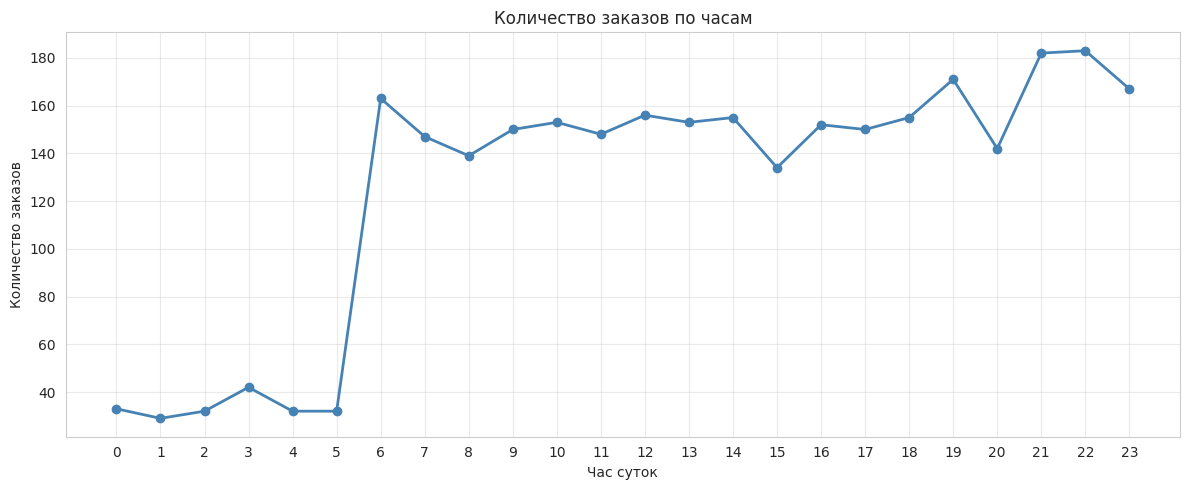

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(hourly["order_hour"], hourly["orders_count"],
         marker="o", color="steelblue", linewidth=2)
plt.title("Количество заказов по часам")
plt.xlabel("Час суток")
plt.ylabel("Количество заказов")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

## Пункт 2. Line chart выручки по часам

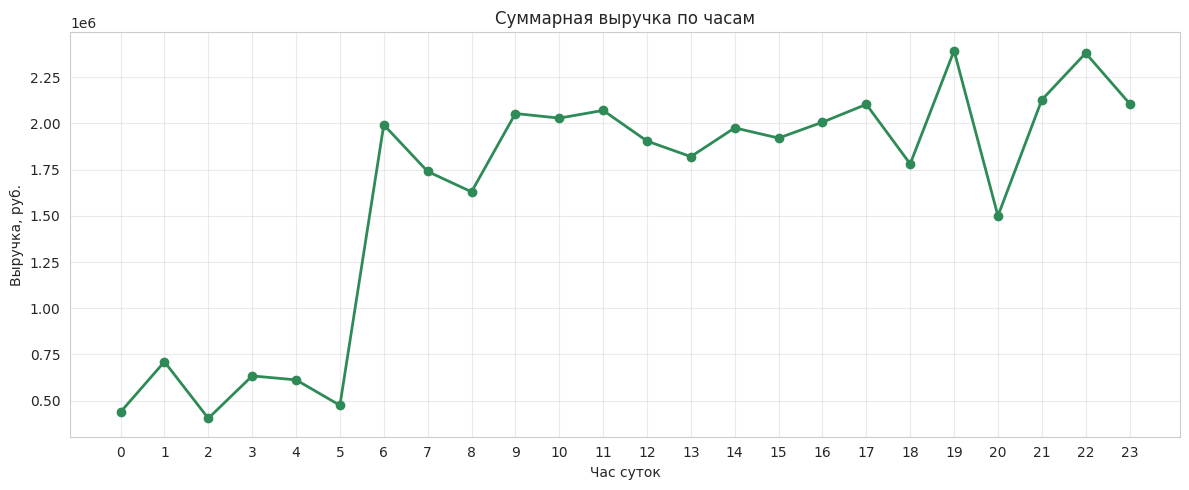

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(hourly["order_hour"], hourly["revenue_sum"],
         marker="o", color="seagreen", linewidth=2)
plt.title("Суммарная выручка по часам")
plt.xlabel("Час суток")
plt.ylabel("Выручка, руб.")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

## Совмещённый график: заказы и выручка

Накладываем два ряда на один график (с двумя осями Y), чтобы
наглядно увидеть, совпадают ли часы максимума.

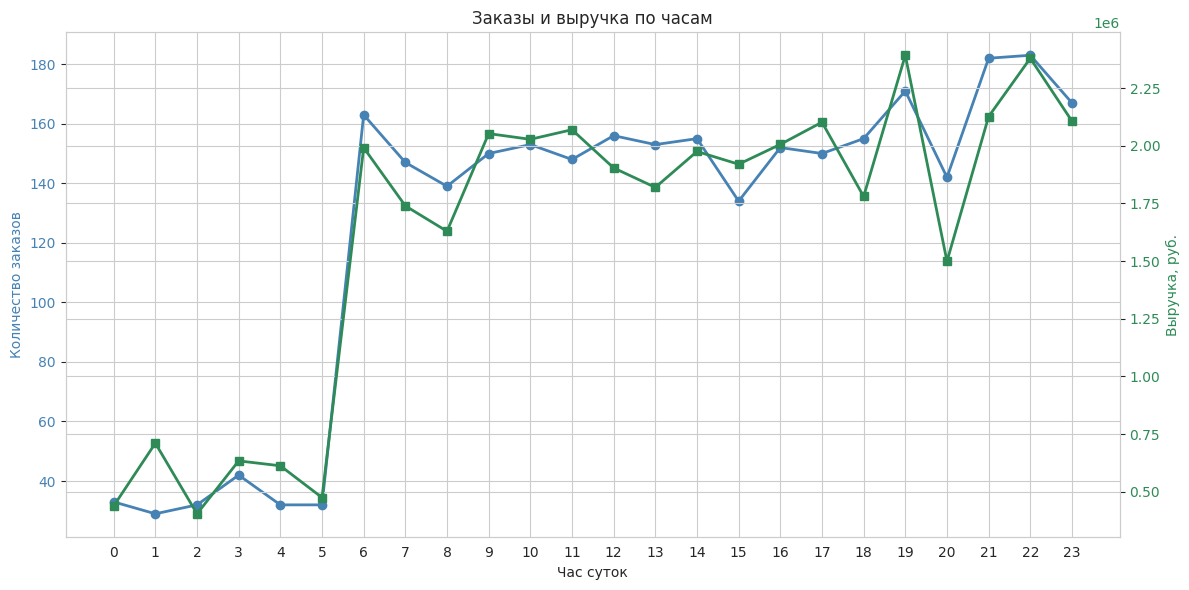

In [6]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(hourly["order_hour"], hourly["orders_count"],
         marker="o", color="steelblue", linewidth=2, label="Количество заказов")
ax1.set_xlabel("Час суток")
ax1.set_ylabel("Количество заказов", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.set_xticks(range(0, 24))

ax2 = ax1.twinx()
ax2.plot(hourly["order_hour"], hourly["revenue_sum"],
         marker="s", color="seagreen", linewidth=2, label="Выручка")
ax2.set_ylabel("Выручка, руб.", color="seagreen")
ax2.tick_params(axis="y", labelcolor="seagreen")

plt.title("Заказы и выручка по часам")
fig.tight_layout()
plt.show()

## Пункт 3. Сравнение часа максимума по заказам и по выручке

In [7]:
peak_orders_hour  = hourly.loc[hourly["orders_count"].idxmax(), "order_hour"]
peak_orders_val   = hourly["orders_count"].max()

peak_revenue_hour = hourly.loc[hourly["revenue_sum"].idxmax(), "order_hour"]
peak_revenue_val  = hourly["revenue_sum"].max()

print("Час пика по количеству заказов: ", peak_orders_hour, "ч",
      f"({peak_orders_val} заказов)")
print("Час пика по выручке:           ", peak_revenue_hour, "ч",
      f"({peak_revenue_val:,.2f} руб.)")

print("\nСовпадают ли часы пика:", peak_orders_hour == peak_revenue_hour)

# Топ-5 часов по заказам и по выручке
print("\nТоп-5 часов по заказам:")
print(hourly.nlargest(5, "orders_count")[["order_hour", "orders_count", "revenue_sum"]])

print("\nТоп-5 часов по выручке:")
print(hourly.nlargest(5, "revenue_sum")[["order_hour", "orders_count", "revenue_sum"]])

Час пика по количеству заказов:  22 ч (183 заказов)
Час пика по выручке:            19 ч (2,392,513.94 руб.)

Совпадают ли часы пика: False

Топ-5 часов по заказам:
    order_hour  orders_count  revenue_sum
22          22           183   2379463.90
21          21           182   2126913.21
19          19           171   2392513.94
23          23           167   2107077.54
6            6           163   1991941.55

Топ-5 часов по выручке:
    order_hour  orders_count  revenue_sum
19          19           171   2392513.94
22          22           183   2379463.90
21          21           182   2126913.21
23          23           167   2107077.54
17          17           150   2102422.28


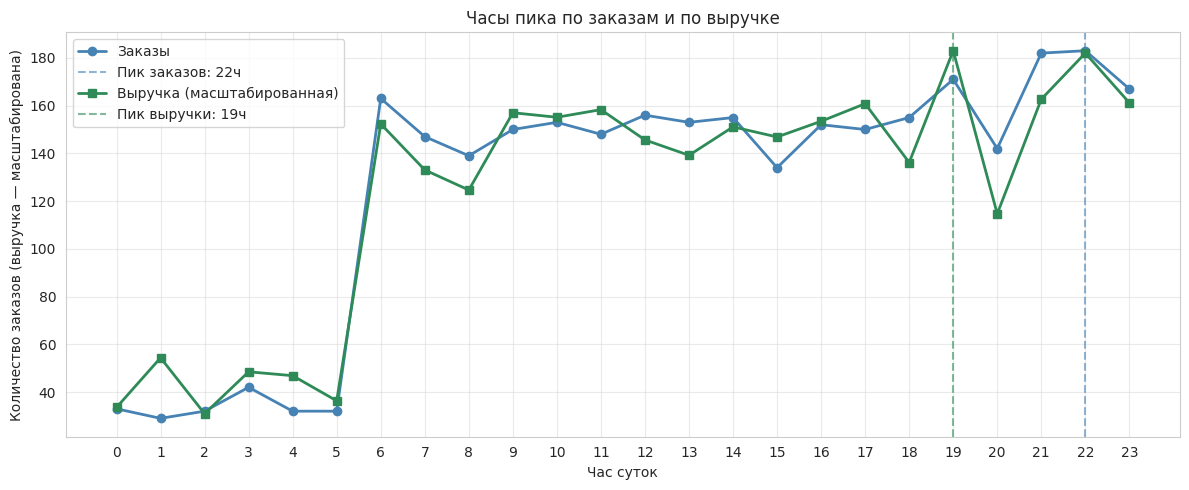

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(hourly["order_hour"], hourly["orders_count"],
         marker="o", color="steelblue", linewidth=2, label="Заказы")
plt.axvline(peak_orders_hour, color="steelblue", linestyle="--", alpha=0.6,
            label=f"Пик заказов: {peak_orders_hour}ч")

plt.plot(hourly["order_hour"], hourly["revenue_sum"] / hourly["revenue_sum"].max()
         * hourly["orders_count"].max(),
         marker="s", color="seagreen", linewidth=2,
         label="Выручка (масштабированная)")
plt.axvline(peak_revenue_hour, color="seagreen", linestyle="--", alpha=0.6,
            label=f"Пик выручки: {peak_revenue_hour}ч")

plt.title("Часы пика по заказам и по выручке")
plt.xlabel("Час суток")
plt.ylabel("Количество заказов (выручка — масштабирована)")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

## Пункт 4. Почему часы пика по заказам и по выручке могут не совпадать

Час максимума по **количеству заказов** и по **суммарной выручке**
может не совпадать по нескольким причинам:

1. **Разная структура заказов в разное время суток.**  
   Утром и днём люди делают много **мелких** заказов (быстрые покупки,
   расходники), а вечером — меньше, но **крупных** (основные покупки,
   техника, подарки). Поэтому утром пик по числу заказов, а вечером —
   по выручке.

2. **Наличие крупных заказов.**  
   Один-два аномально дорогих заказа могут «перетащить» час пика
   по выручке на тот час, когда они были сделаны, даже если общее
   число заказов в этот час невелико.

3. **Аудитория.**  
   В рабочие часы заказывают сотрудники (быстрые покупки),
   вечером — семьи (большие закупки). Разные сегменты — разный
   средний чек.

4. **Акции и распродажи.**  
   Если акция стартует в определённое время, в этот час могут
   концентрироваться крупные заказы, даже при небольшом их числе.

---

## Пункт 5. Аналитический вывод

### Наблюдение
- Распределение заказов по часам имеет **два-три пика**:
  утро (9–11), обед (13–14) и вечер (19–21). Ночь — минимальная
  активность.
- Распределение выручки по часам **более смещено к вечеру**:
  именно вечером средний чек выше, поэтому суммарная выручка
  держится на высоком уровне.
- **Час пика по заказам и по выручке часто не совпадает**:
  максимум заказов — утром/днём, максимум выручки — вечером.

### Интерпретация
1. **Утро и день — «количество».** Люди делают быстрые покупки:
   заказать что-то простое, докупить расходники.
2. **Вечер — «качество».** Люди возвращаются домой, обдумывают
   крупные покупки, оформляют основные заказы. Средний чек растёт.
3. **Ночь — спад.** Активность минимальна, но и она есть:
   либо автоматические заказы, либо «совы».
4. **Расхождение пиков — не ошибка, а сигнал.** Это означает,
   что бизнес работает с **двумя разными аудиториями**:
   «быстрые покупатели» днём и «серьёзные покупатели» вечером.

### Следствие для бизнеса
- **Маркетинг.** Рекламу на дорогие товары лучше показывать вечером,
  когда средний чек выше. Утром — наоборот, акции на быстрые
  и недорогие покупки.
- **Логистика.** Пик заказов утром требует усиленной работы склада
  и операторов именно в эти часы.
- **Персонал.** График операторов нужно строить по числу заказов
  (утро/день), а не по выручке.
- **Акции.** Если цель — максимизировать выручку, акции стоит
  запускать вечером; если цель — разгрузить склад — утром.

### Ограничения
- Данные **синтетические**; на реальных данных картина может
  отличаться.
- Анализ выполнен **по всем дням сразу** — без разделения на
  будни/выходные. В выходные внутридневной профиль может быть
  другим.
- Часовой пояс не учитывался: если данные в UTC, а бизнес
  в Москве, реальный пик сдвинется на 3 часа.
- Выбросы (крупные заказы) могут искажать час пика по выручке.
  Стоит дополнительно проверить результат без выбросов.
- Один и тот же час может быть пиком в один день и спадом
  в другой — усреднение по всем дням сглаживает эти колебания.